# Actividad 4. Filtros y controles interactivos

En esta actividad agrego los controles para que el usuario decida **qué variable**
ver, **en qué periodo** y **con qué tipo de desastre**. Aquí reviso los datos y
dejo preparado el archivo que consultan los filtros de la app.

Todos los nombres de desastres los muestro en español, usando el diccionario
que armo en el Paso 4.


# Paso 1. Preparo las librerías

In [1]:
%pip install pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Paso 2. Importo lo que necesito

In [2]:
import sys
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt

# La raíz del proyecto es la carpeta que contiene src/ y notebooks/.
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

CARPETA_GRAFICAS = RAIZ / 'resultados' / 'graficas' / 'filtros'
CARPETA_GRAFICAS.mkdir(parents=True, exist_ok=True)

print(RAIZ)

C:\Users\itzel\PROYECTO_DESASTRES


# Paso 3. Reviso el periodo y los tipos de desastre

Primero necesito saber entre qué años se mueve el dataset y cuántos tipos de
desastre hay. Eso define el rango de los sliders y el contenido del selector.


In [3]:
from src.generar_filtros import cargar_eventos

eventos = cargar_eventos()

print(f'Eventos           : {len(eventos):,}')
print(f'Países            : {eventos["iso"].nunique()}')
print(f'Periodo           : {eventos["anio"].min()} - {eventos["anio"].max()}')
print(f'Tipos de desastre : {eventos["tipo"].nunique()}')

Eventos           : 10,907
Países            : 220
Periodo           : 2000 - 2026
Tipos de desastre : 14


# Paso 4. Armo el diccionario de nombres en español

EM-DAT guarda los tipos en inglés. Para que los filtros y las gráficas se lean
en español, defino el diccionario una sola vez en `src/diccionario_desastres.py`
y desde ahí genero el archivo JavaScript que usa la app.

Así no tengo dos listas distintas que se puedan desincronizar.


In [4]:
from src.diccionario_desastres import DICCIONARIO, traducir, exportar_js

ruta_js = exportar_js()
print(f'Diccionario exportado a la app: {ruta_js.relative_to(RAIZ)}')
print(f'Traducciones: {len(DICCIONARIO)}')

# Reviso que ningún tipo del dataset se quede sin traducción.
tipos = sorted(eventos['tipo'].unique())
sin_traduccion = [t for t in tipos if t not in DICCIONARIO]
print(f'Tipos sin traducción: {sin_traduccion if sin_traduccion else "ninguno"}')

pd.DataFrame({'tipo_original': tipos, 'nombre_en_español': [traducir(t) for t in tipos]})

Diccionario exportado a la app: app\js\diccionario_desastres.js
Traducciones: 14
Tipos sin traducción: ninguno


,tipo_original,nombre_en_español
0,Animal incident,Incidente con animales
1,Drought,Sequía
2,Earthquake,Terremoto
3,Epidemic,Epidemia
4,Extreme temperature,Temperatura extrema
5,Flood,Inundación
6,Glacial lake outburst flood,Ruptura de lago glacial
7,Impact,Impacto
8,Infestation,Infestación
9,Mass movement (dry),Deslizamiento (seco)


# Paso 5. Cuento los eventos por año

Así veo cómo se reparte el periodo. Es lo que el usuario va a recorrer con los
sliders.


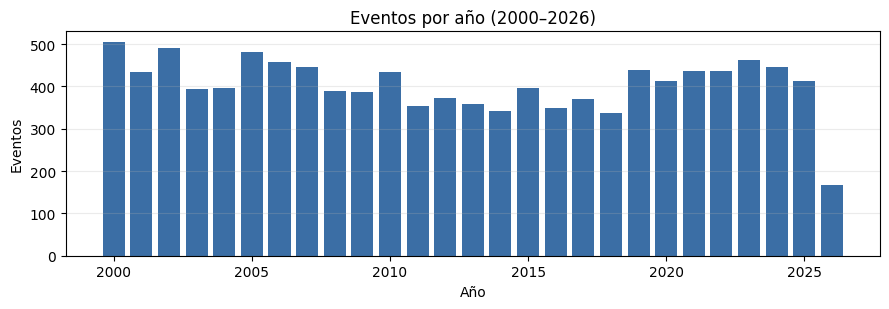

,anio,eventos
19,2019,438
20,2020,414
21,2021,437
22,2022,436
23,2023,462
24,2024,447
25,2025,412
26,2026,166


In [5]:
por_anio = (
    eventos.groupby('anio')
    .size()
    .reset_index(name='eventos')
)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(por_anio['anio'], por_anio['eventos'], color='#3b6ea5')
ax.set_title('Eventos por año (2000–2026)')
ax.set_xlabel('Año')
ax.set_ylabel('Eventos')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(CARPETA_GRAFICAS / '01_eventos_por_anio.png', dpi=150)
plt.show()

por_anio.tail(8)

# Paso 6. Cuento los eventos por tipo de desastre

Este es el orden en el que aparecen las opciones del selector. Los nombres van
en español, como en la aplicación.


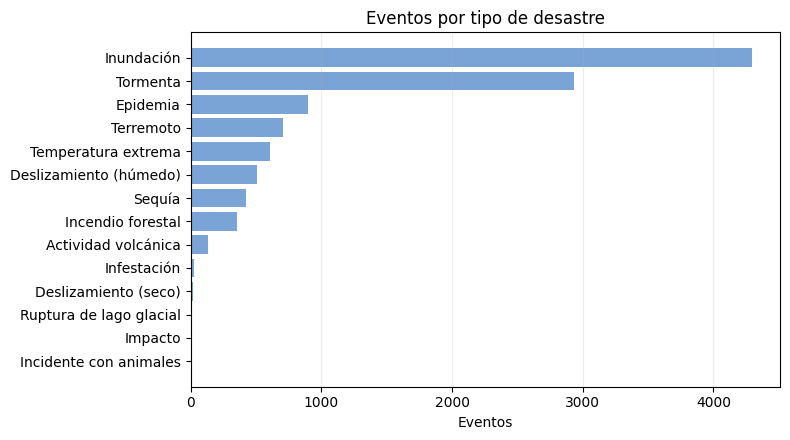

,desastre,eventos
0,Inundación,4294
1,Tormenta,2930
2,Epidemia,895
3,Terremoto,707
4,Temperatura extrema,606
5,Deslizamiento (húmedo),505
6,Sequía,426
7,Incendio forestal,356
8,Actividad volcánica,134
9,Infestación,29


In [6]:
por_tipo = (
    eventos.groupby('tipo')
    .size()
    .reset_index(name='eventos')
    .assign(desastre=lambda d: d['tipo'].map(traducir))
    .sort_values('eventos')
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(por_tipo['desastre'], por_tipo['eventos'], color='#7aa3d6')
ax.set_title('Eventos por tipo de desastre')
ax.set_xlabel('Eventos')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(CARPETA_GRAFICAS / '02_eventos_por_tipo.png', dpi=150)
plt.show()

(
    por_tipo[['desastre', 'eventos']]
    .sort_values('eventos', ascending=False)
    .reset_index(drop=True)
)

# Paso 7. Genero el archivo de los filtros

El mapa ya trae los totales por país, pero no el detalle por año y por tipo. Si
el navegador tuviera que leer el CSV completo cada vez que se mueve un slider,
sería muy lento.

Por eso genero `app/datos/filtros.json` con el detalle **país × año × tipo**.
Así el filtrado se hace en el navegador, al instante y sin volver a procesar el
dataset.

Los montos salen ya en **pesos mexicanos**, porque el dataset se convierte
antes con `src/moneda.py` (tipo de cambio fijo de 1 USD = 20.8 MXN).

In [7]:
from src.generar_filtros import generar

ruta_filtros = generar()

print(f'Archivo : {ruta_filtros.relative_to(RAIZ)}')
print(f'Tamaño  : {ruta_filtros.stat().st_size / 1024:.0f} KB')

Archivo : app\datos\filtros.json
Tamaño  : 211 KB


# Paso 8. Reviso el archivo generado

In [8]:
contenido = json.loads(ruta_filtros.read_text(encoding='utf-8'))

n_paises = len(contenido['datos'])
n_combinaciones = sum(len(filas) for filas in contenido['datos'].values())

print(f'Periodo       : {contenido["periodo"]["inicio"]} - {contenido["periodo"]["fin"]}')
print(f'Países        : {n_paises}')
print(f'Tipos         : {len(contenido["tipos"])}')
print(f'Combinaciones : {n_combinaciones:,}')

# Reviso México como ejemplo: año, tipo, eventos, fallecidos, afectados, daño.
print('\nPrimeras filas de México:')
for fila in contenido['datos']['MEX'][:5]:
    anio, tipo, ev, fa, af, da = fila
    print(f'  {anio} · {traducir(tipo):<24} eventos={ev}  fallecidos={fa}  afectados={af}')

Periodo       : 2000 - 2026
Países        : 220
Tipos         : 14
Combinaciones : 6,185

Primeras filas de México:
  2000 · Temperatura extrema      eventos=1  fallecidos=66  afectados=0
  2000 · Inundación               eventos=3  fallecidos=139  afectados=2000
  2000 · Tormenta                 eventos=2  fallecidos=31  afectados=30300
  2000 · Actividad volcánica      eventos=1  fallecidos=0  afectados=41000
  2001 · Inundación               eventos=1  fallecidos=21  afectados=0


# Paso 9. Simulo el filtro que hace la app

Antes de tocar JavaScript compruebo que la lógica funciona aquí. Filtro
**2015–2026** y **solo inundaciones**, igual que haría el usuario en el panel.


In [9]:
def filtrar(datos, anio_inicio, anio_fin, tipo=None):
    """Suma los eventos de cada país dentro del periodo y tipo indicados."""
    resultado = {}

    for iso, filas in datos.items():
        eventos_pais = fallecidos = afectados = dano = 0

        for anio, tipo_fila, ev, fa, af, da in filas:
            if anio < anio_inicio or anio > anio_fin:
                continue
            if tipo and tipo_fila != tipo:
                continue
            eventos_pais += ev
            fallecidos += fa
            afectados += af
            dano += da

        if eventos_pais:
            resultado[iso] = {
                'eventos': eventos_pais,
                'fallecidos': fallecidos,
                'afectados': afectados,
                'dano_mxn': dano,
            }

    return resultado


PRUEBA_INICIO, PRUEBA_FIN, PRUEBA_TIPO = 2015, 2026, 'Flood'

filtrado = filtrar(contenido['datos'], PRUEBA_INICIO, PRUEBA_FIN, tipo=PRUEBA_TIPO)

print(f'Filtro aplicado        : {traducir(PRUEBA_TIPO)} · {PRUEBA_INICIO}-{PRUEBA_FIN}')
print(f'Países con eventos     : {len(filtrado)}')
print(f'Eventos en el filtro   : {sum(v["eventos"] for v in filtrado.values()):,}')

tabla_filtro = (
    pd.DataFrame(filtrado).T
    .sort_values('eventos', ascending=False)
    .head(5)
    .astype({'eventos': int, 'fallecidos': int, 'afectados': int})
)
tabla_filtro

Filtro aplicado        : Inundación · 2015-2026
Países con eventos     : 154
Eventos en el filtro   : 1,841


,eventos,fallecidos,afectados,dano_mxn
IDN,123,1123,4482995,4.843567e+10
CHN,81,4025,117421786,3.159004e+12
IND,79,13525,100407598,9.924594e+11
BRA,63,1250,5230229,2.326684e+11
USA,50,478,164384,1.241215e+12


Comparo con el total del periodo completo para asegurarme de que el filtro
realmente reduce los datos.


In [10]:
total_completo = filtrar(contenido['datos'], 2000, 2026)
solo_inundaciones = filtrar(contenido['datos'], 2000, 2026, tipo=PRUEBA_TIPO)

resumen = pd.DataFrame(
    [
        {'filtro': 'Todo el periodo', 'paises': len(total_completo),
         'eventos': sum(v['eventos'] for v in total_completo.values())},
        {'filtro': traducir(PRUEBA_TIPO), 'paises': len(solo_inundaciones),
         'eventos': sum(v['eventos'] for v in solo_inundaciones.values())},
        {'filtro': f'{traducir(PRUEBA_TIPO)} {PRUEBA_INICIO}-{PRUEBA_FIN}',
         'paises': len(filtrado),
         'eventos': sum(v['eventos'] for v in filtrado.values())},
    ]
)
resumen

,filtro,paises,eventos
0,Todo el periodo,220,10907
1,Inundación,181,4294
2,Inundación 2015-2026,154,1841


# Paso 10. Compruebo que los controles están en la app

Reviso que el HTML tenga los controles y que el JavaScript tenga la lógica que
los conecta.


In [11]:
import re

html = (RAIZ / 'app' / 'index.html').read_text(encoding='utf-8')
js_app = (RAIZ / 'app' / 'js' / 'app.js').read_text(encoding='utf-8')
js_capa = (RAIZ / 'app' / 'js' / 'capa_tematica.js').read_text(encoding='utf-8')
js_dicc = (RAIZ / 'app' / 'js' / 'diccionario_desastres.js').read_text(encoding='utf-8')

controles = {
    'Slider de año mínimo'   : 'filtro-anio-min' in html,
    'Slider de año máximo'   : 'filtro-anio-max' in html,
    'Selector de tipo'       : 'selector-tipo' in html,
    'Activar / desactivar'   : 'chk-aplicar-filtros' in html,
    'Botón restablecer'      : 'btn-reset-filtros' in html,
    'Filtrar al mover'       : 'aplicarFiltros' in js_app,
    'Recalcular la capa'     : 'setFiltro' in js_capa,
    'Restaurar sin filtros'  : 'quitarFiltro' in js_capa,
    'Diccionario en español' : 'DICCIONARIO_DESASTRES' in js_dicc,
}

# Confirmo que las 14 traducciones llegaron al archivo de JavaScript.
traducciones_js = len(re.findall(r'^\s+"[^"]+":\s+"[^"]+"', js_dicc, flags=re.M))
print(f'Traducciones presentes en el JS: {traducciones_js} de {len(DICCIONARIO)}')

pd.DataFrame(
    {'control': list(controles.keys()), 'presente': list(controles.values())}
)

Traducciones presentes en el JS: 14 de 14


,control,presente
0,Slider de año mínimo,True
1,Slider de año máximo,True
2,Selector de tipo,True
3,Activar / desactivar,True
4,Botón restablecer,True
5,Filtrar al mover,True
6,Recalcular la capa,True
7,Restaurar sin filtros,True
8,Diccionario en español,True


Los filtros quedaron así:

* **Periodo**: dos sliders de 2000 a 2026, que se ajustan entre sí.
* **Tipo de desastre**: selector con los 14 tipos, siempre en español.
* **Aplicar filtros**: casilla para activar o desactivar el filtrado.
* **Restablecer**: vuelve al periodo completo y a todos los tipos.

Los nombres en español salen de un único diccionario, el mismo que usan las
gráficas de este notebook y la aplicación.
